# SC4001 Adaptive RAG output analysis

This notebook analyzes the 500-question runs in `outputs_v2/`, saves report figures under `analysis/figures/`, and displays every figure inline.

In [1]:
import csv
import json
from pathlib import Path

import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "analysis" else Path.cwd()
OUTPUTS = ROOT / "outputs_v2"
ANALYSIS = ROOT / "analysis"
FIGURES = ANALYSIS / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

RUNS = [
    ("Top-2", "baseline_top2_single_shot_n500_seed88", "#4C78A8"),
    ("Top-3", "baseline_top3_single_shot_n500_seed88", "#72B7B2"),
    ("Top-4", "baseline_top4_single_shot_n500_seed88", "#F2CF5B"),
    ("Top-5", "baseline_top5_single_shot_n500_seed88", "#F58518"),
    ("Adaptive V3", "adaptive_v3_top2_unseen_n500_seed88", "#E45756"),
]

def load_summary(folder):
    with (OUTPUTS / folder / "summary.json").open(encoding="utf-8") as handle:
        return json.load(handle)

def style_axis(ax, title, ylabel):
    ax.set_title(title, fontsize=12, weight="bold")
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)


In [2]:
rows = []
for label, folder, _ in RUNS:
    summary = load_summary(folder)
    rows.append({
        "method": label,
        "mean_gold_evidence_pct": summary["gold_evidence_percentage"]["mean"],
        "full_gold_recovery_pct": 100 * summary["full_gold_recovery_rate"],
        "zero_gold_recovery_pct": 100 * summary["zero_gold_recovery_rate"],
        "mean_noise_pct": summary["noise_percentage"]["mean"],
        "mean_paragraphs": summary["raw_paragraphs_retrieved"]["mean"],
        "mean_rounds": summary["retrieval_rounds"]["mean"],
        "mean_reasoning_calls": summary["reasoning_model_calls"]["total"]["mean"],
    })

with (ANALYSIS / "metrics_500.csv").open("w", newline="", encoding="utf-8") as handle:
    writer = csv.DictWriter(handle, fieldnames=list(rows[0]))
    writer.writeheader()
    writer.writerows(rows)

rows


[{'method': 'Top-2',
  'mean_gold_evidence_pct': 60.3,
  'full_gold_recovery_pct': 29.599999999999998,
  'zero_gold_recovery_pct': 9.0,
  'mean_noise_pct': 39.7,
  'mean_paragraphs': 2,
  'mean_rounds': 1,
  'mean_reasoning_calls': 0},
 {'method': 'Top-3',
  'mean_gold_evidence_pct': 71.2,
  'full_gold_recovery_pct': 47.199999999999996,
  'zero_gold_recovery_pct': 4.8,
  'mean_noise_pct': 52.400000000000006,
  'mean_paragraphs': 2.996,
  'mean_rounds': 1,
  'mean_reasoning_calls': 0},
 {'method': 'Top-4',
  'mean_gold_evidence_pct': 78.0,
  'full_gold_recovery_pct': 58.599999999999994,
  'zero_gold_recovery_pct': 2.6,
  'mean_noise_pct': 60.766666666666666,
  'mean_paragraphs': 3.99,
  'mean_rounds': 1,
  'mean_reasoning_calls': 0},
 {'method': 'Top-5',
  'mean_gold_evidence_pct': 83.3,
  'full_gold_recovery_pct': 68.2,
  'zero_gold_recovery_pct': 1.6,
  'mean_noise_pct': 66.38666666666667,
  'mean_paragraphs': 4.984,
  'mean_rounds': 1,
  'mean_reasoning_calls': 0},
 {'method': 'Adapt

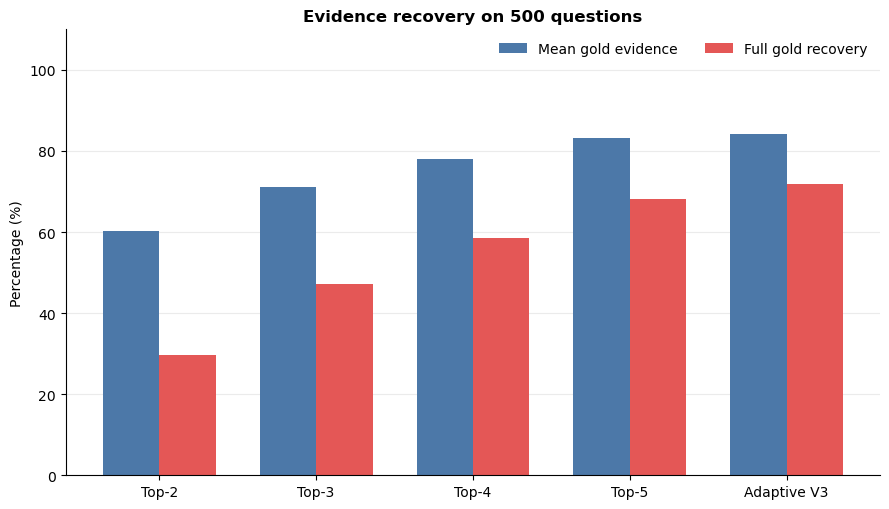

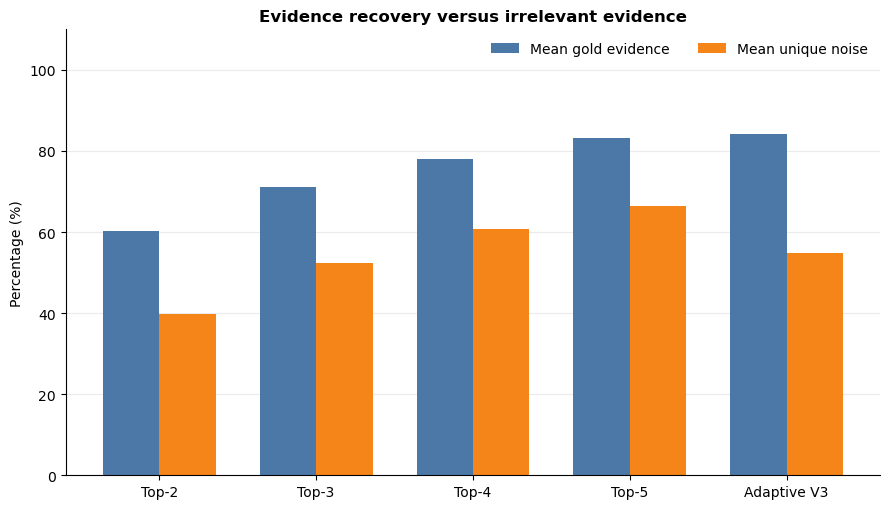

In [3]:
labels = [row["method"] for row in rows]
x = range(len(labels))
width = 0.36
fig, ax = plt.subplots(figsize=(9, 5.2))
ax.bar([i - width / 2 for i in x], [r["mean_gold_evidence_pct"] for r in rows], width, label="Mean gold evidence", color="#4C78A8")
ax.bar([i + width / 2 for i in x], [r["full_gold_recovery_pct"] for r in rows], width, label="Full gold recovery", color="#E45756")
ax.set_xticks(list(x), labels)
ax.set_ylim(0, 110)
style_axis(ax, "Evidence recovery on 500 questions", "Percentage (%)")
ax.legend(frameon=False, ncol=2)
fig.tight_layout()
fig.savefig(FIGURES / "01_evidence_recovery.png", dpi=220)
plt.show()

fig, ax = plt.subplots(figsize=(9, 5.2))
ax.bar([i - width / 2 for i in x], [r["mean_gold_evidence_pct"] for r in rows], width, label="Mean gold evidence", color="#4C78A8")
ax.bar([i + width / 2 for i in x], [r["mean_noise_pct"] for r in rows], width, label="Mean unique noise", color="#F58518")
ax.set_xticks(list(x), labels)
ax.set_ylim(0, 110)
style_axis(ax, "Evidence recovery versus irrelevant evidence", "Percentage (%)")
ax.legend(frameon=False, ncol=2)
fig.tight_layout()
fig.savefig(FIGURES / "02_recovery_noise_tradeoff.png", dpi=220)
plt.show()


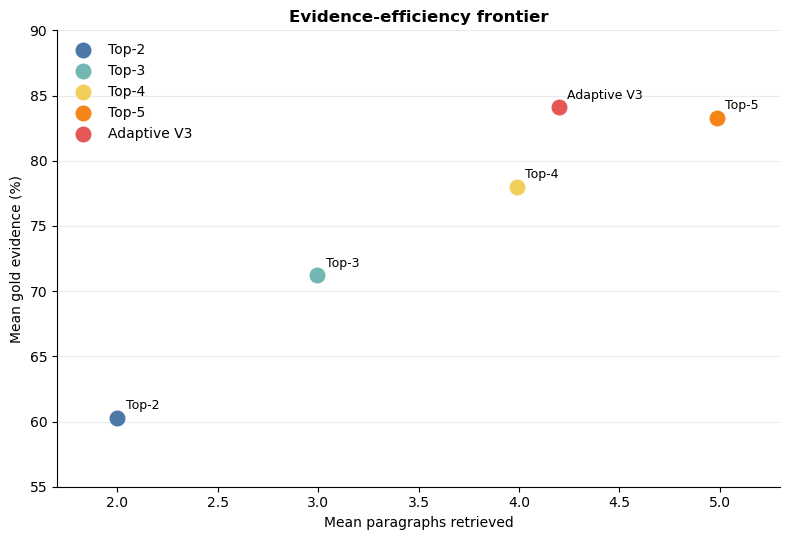

In [4]:
fig, ax = plt.subplots(figsize=(8, 5.5))
for row, (_, _, color) in zip(rows, RUNS, strict=True):
    ax.scatter(row["mean_paragraphs"], row["mean_gold_evidence_pct"], s=110, color=color, label=row["method"], zorder=3)
    ax.annotate(row["method"], (row["mean_paragraphs"], row["mean_gold_evidence_pct"]), xytext=(6, 6), textcoords="offset points", fontsize=9)

style_axis(ax, "Evidence-efficiency frontier", "Mean gold evidence (%)")
ax.set_xlabel("Mean paragraphs retrieved")
ax.set_xlim(1.7, 5.3)
ax.set_ylim(55, 90)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURES / "03_efficiency_frontier.png", dpi=220)
plt.show()


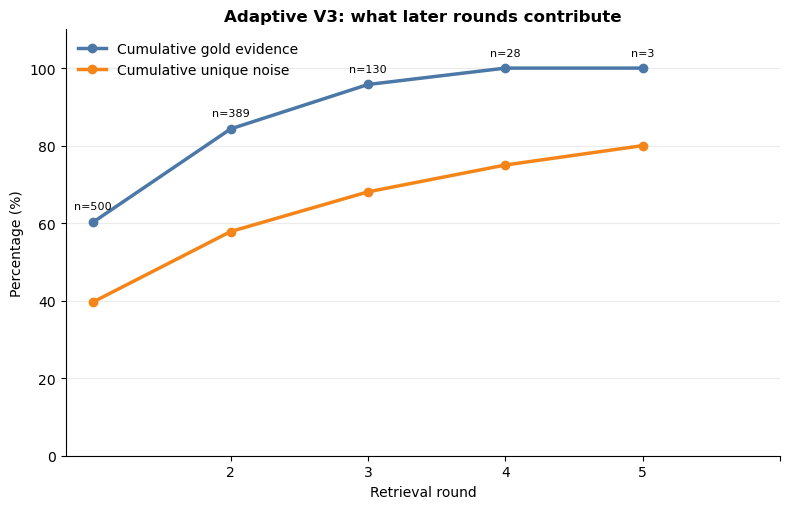

In [5]:
summary = load_summary("adaptive_v3_top2_unseen_n500_seed88")
diagnostics = summary["controller_diagnostics"]["gold_recovery_by_round"]
rounds = sorted(diagnostics, key=int)
active = [diagnostics[r]["questions_reaching_round"] for r in rounds]
gold = [diagnostics[r]["mean_cumulative_gold_recall_percentage"] for r in rounds]
noise = [diagnostics[r]["mean_cumulative_unique_noise_percentage"] for r in rounds]

fig, ax = plt.subplots(figsize=(8, 5.2))
ax.plot(rounds, gold, marker="o", linewidth=2.5, label="Cumulative gold evidence", color="#4C78A8")
ax.plot(rounds, noise, marker="o", linewidth=2.5, label="Cumulative unique noise", color="#F58518")
for round_number, count, value in zip(rounds, active, gold, strict=True):
    ax.annotate(f"n={count}", (round_number, value), xytext=(0, 9), textcoords="offset points", ha="center", fontsize=8)
ax.set_xticks([int(r) for r in rounds])
ax.set_ylim(0, 110)
style_axis(ax, "Adaptive V3: what later rounds contribute", "Percentage (%)")
ax.set_xlabel("Retrieval round")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURES / "04_v3_round_progression.png", dpi=220)
plt.show()


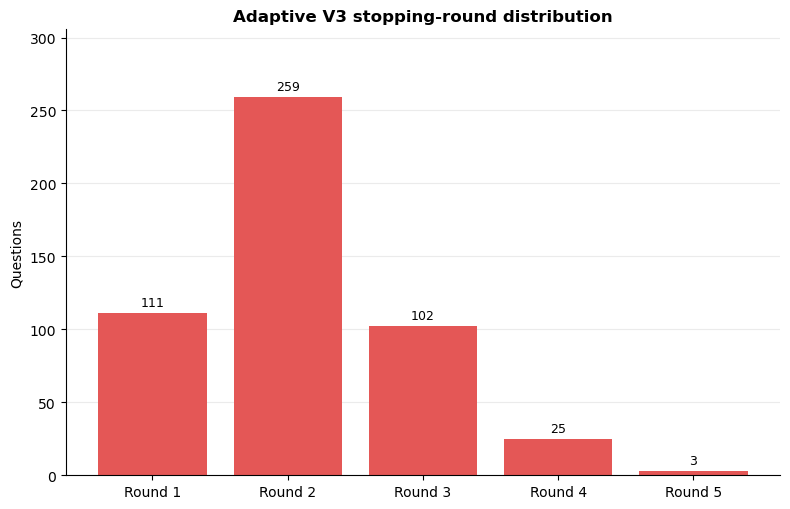

In [6]:
counts = summary["stopping_round_counts"]
labels = [f"Round {r}" for r in sorted(counts, key=int)]
values = [counts[r] for r in sorted(counts, key=int)]
fig, ax = plt.subplots(figsize=(8, 5.2))
bars = ax.bar(labels, values, color="#E45756")
for bar, value in zip(bars, values, strict=True):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 5, str(value), ha="center", fontsize=9)
style_axis(ax, "Adaptive V3 stopping-round distribution", "Questions")
ax.set_ylim(0, max(values) * 1.18)
fig.tight_layout()
fig.savefig(FIGURES / "05_v3_stopping_rounds.png", dpi=220)
plt.show()


In [7]:
assert len(rows) == 5
assert round(rows[-1]["mean_gold_evidence_pct"], 1) == 84.1
assert round(rows[-1]["full_gold_recovery_pct"], 1) == 71.8
assert round(rows[-1]["mean_noise_pct"], 2) == 54.78
assert round(rows[-1]["mean_paragraphs"], 2) == 4.20
assert all((FIGURES / f"0{i}_{name}.png").exists() for i, name in enumerate([
    "evidence_recovery", "recovery_noise_tradeoff", "efficiency_frontier", "v3_round_progression", "v3_stopping_rounds"
], start=1))
print("Notebook analysis validation passed; all five figures are saved and displayed above.")


Notebook analysis validation passed; all five figures are saved and displayed above.


## Advanced paired analyses

This section adds paired bootstrap confidence intervals and controller stopping quality.

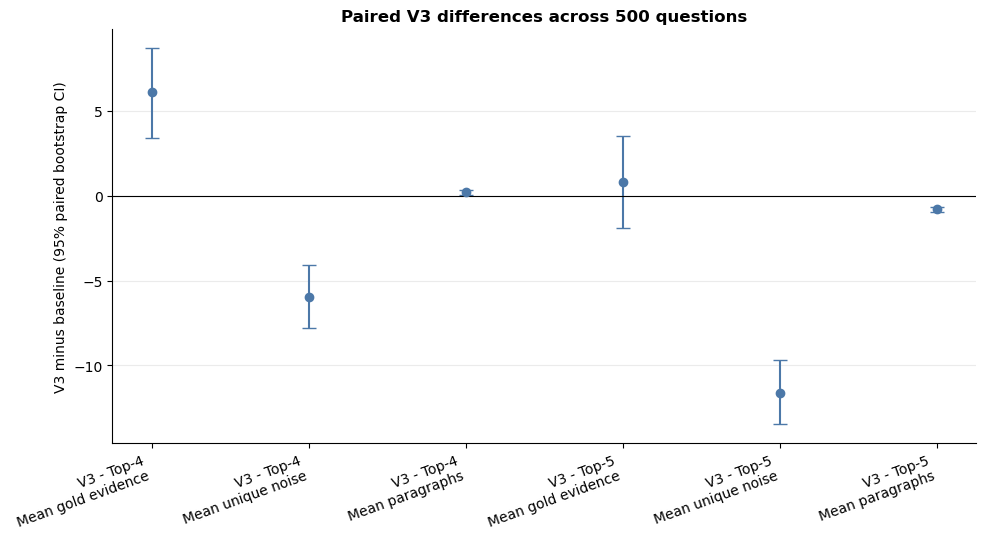

Wrote advanced analysis tables, summary, and three figures.


In [8]:
#!/usr/bin/env python3
"""Generate paired uncertainty and stopping-quality analyses."""

from __future__ import annotations

import csv
import json
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np


ROOT = Path.cwd().parent if Path.cwd().name == "analysis" else Path.cwd()
OUTPUTS = ROOT / "outputs_v2"
ANALYSIS = ROOT / "analysis"
FIGURES = ANALYSIS / "figures"
V3_PATH = OUTPUTS / "adaptive_v3_top2_unseen_n500_seed88" / "results.jsonl"


def load_records(path: Path) -> list[dict]:
    with path.open(encoding="utf-8") as handle:
        return [json.loads(line) for line in handle]


def paired_values(folder: str, metric: str) -> tuple[np.ndarray, np.ndarray]:
    baseline = load_records(OUTPUTS / folder / "results.jsonl")
    v3 = load_records(V3_PATH)
    if [row["question_id"] for row in baseline] != [row["question_id"] for row in v3]:
        raise ValueError(f"question ordering differs for {folder}")
    return (
        np.array([row[metric] for row in baseline], dtype=float),
        np.array([row[metric] for row in v3], dtype=float),
    )


def bootstrap_ci(differences: np.ndarray, seed: int = 88) -> tuple[float, float, float]:
    rng = np.random.default_rng(seed)
    samples = differences[rng.integers(0, len(differences), size=(10_000, len(differences)))]
    means = samples.mean(axis=1)
    return float(differences.mean()), float(np.percentile(means, 2.5)), float(np.percentile(means, 97.5))


def paired_confidence_intervals() -> list[dict]:
    rows = []
    for label, folder in (("Top-4", "baseline_top4_single_shot_n500_seed88"),
                          ("Top-5", "baseline_top5_single_shot_n500_seed88")):
        for metric, display in (("gold_evidence_percentage", "Mean gold evidence"),
                                ("noise_percentage", "Mean unique noise"),
                                ("raw_paragraphs_retrieved", "Mean paragraphs")):
            baseline, v3 = paired_values(folder, metric)
            mean_delta, lower, upper = bootstrap_ci(v3 - baseline)
            rows.append({"comparison": f"V3 - {label}", "metric": display,
                         "mean_delta": mean_delta, "ci_lower": lower, "ci_upper": upper})
    return rows



def save_csv(path: Path, rows: list[dict]) -> None:
    with path.open("w", newline="", encoding="utf-8") as handle:
        writer = csv.DictWriter(handle, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)


def save_confidence_figure(rows: list[dict]) -> None:
    labels = [f"{row['comparison']}\n{row['metric']}" for row in rows]
    means = [row["mean_delta"] for row in rows]
    errors = [
        [row["mean_delta"] - row["ci_lower"] for row in rows],
        [row["ci_upper"] - row["mean_delta"] for row in rows],
    ]
    fig, ax = plt.subplots(figsize=(10, 5.5))
    ax.errorbar(range(len(rows)), means, yerr=errors, fmt="o", capsize=5, color="#4C78A8")
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_xticks(range(len(rows)), labels, rotation=20, ha="right")
    ax.set_ylabel("V3 minus baseline (95% paired bootstrap CI)")
    ax.set_title("Paired V3 differences across 500 questions", weight="bold")
    ax.grid(axis="y", alpha=0.25)
    ax.spines[["top", "right"]].set_visible(False)
    fig.tight_layout()
    fig.savefig(FIGURES / "06_paired_bootstrap_ci.png", dpi=220)
    plt.show()
    plt.close(fig)




def stopping_rows() -> list[dict]:
    rows = load_records(V3_PATH)
    grouped = Counter(row["stop_reason"] for row in rows)
    result = []
    for reason, count in sorted(grouped.items()):
        subset = [row for row in rows if row["stop_reason"] == reason]
        complete = sum(row["gold_evidence_percentage"] == 100 for row in subset)
        result.append({"stop_reason": reason, "questions": count,
                       "gold_complete": complete,
                       "gold_complete_pct": 100 * complete / count})
    return result


def main() -> None:
    FIGURES.mkdir(parents=True, exist_ok=True)
    ci_rows = paired_confidence_intervals()
    stop_rows = stopping_rows()
    save_csv(ANALYSIS / "paired_bootstrap_ci.csv", ci_rows)
    save_csv(ANALYSIS / "stopping_quality.csv", stop_rows)
    save_confidence_figure(ci_rows)
    print("Wrote advanced analysis tables, summary, and three figures.")


if __name__ == "__main__":
    main()
